# Introduction

This notebook explores chemical properties of wine, suchas acidity, sugar, pH and how it influences something subjective like "quality."  
In short, can chemistry predict taste?

This notebook uses the dataset available from the UCI Machine Learning Repository.  
https://archive.ics.uci.edu/dataset/186/wine+quality

In [ ]:
!pip install ucimlrepo

In [2]:
# import statements
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# import statement as given by UCI

try: 
    # fetch dataset from UCI's machine learning repository
    wine_quality = fetch_ucirepo(id=186) 
     
    # data (as pandas dataframes) 
    X = wine_quality.data.features 
    y = wine_quality.data.targets
    
    # metadata 
    print(wine_quality.metadata) 
      
    # variable information 
    print(wine_quality.variables) 
    
except:
    # in the event the servers are unreachable through API then use a local copy
    print("There's an issue connecting to UCI servers, using local copy instead.")
    
    # wine quality is split into two datasets, when downloaded through ucirepo both datasets are combined into one
    red = pd.read_csv("winequality-red.csv", sep=";")
    white = pd.read_csv("winequality-white.csv", sep=";")
    
    # combine both datasets into one set
    wine_quality = pd.concat([red, white], ignore_index=True)
    
    # rename the columns to conform to the column names downloaded from the ucirepo
    wine_quality.columns = wine_quality.columns.str.replace(" ", "_")
    
    # create the same dataframes as the ucirepo documentation
    X = wine_quality.drop(columns=["quality"])
    y = wine_quality["quality"]

{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [4]:

print ("dataframe shape:", X.shape)
X.dtypes

dataframe shape: (6497, 11)


fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object

In [5]:
total_nans = X.isna().sum().sum()

print("Total nans:", total_nans)

Total nans: 0


In [6]:
y.describe()

,quality
count,6497.000000
mean,5.818378
std,0.873255
min,3.000000
25%,5.000000
50%,6.000000
75%,6.000000
max,9.000000


### Data Exploration

The data is very clean and ready to work with.  
The `X` dataframe is the feature set of the data. Whereas `y` is only the quality.  
The data is split by the `ucimlrepo` package to cleanly interface with `scikit‑learn`.

In [7]:
# combine the data into a single dataframe for exploration
wine_df = pd.concat([X, y], axis=1)
wine_df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


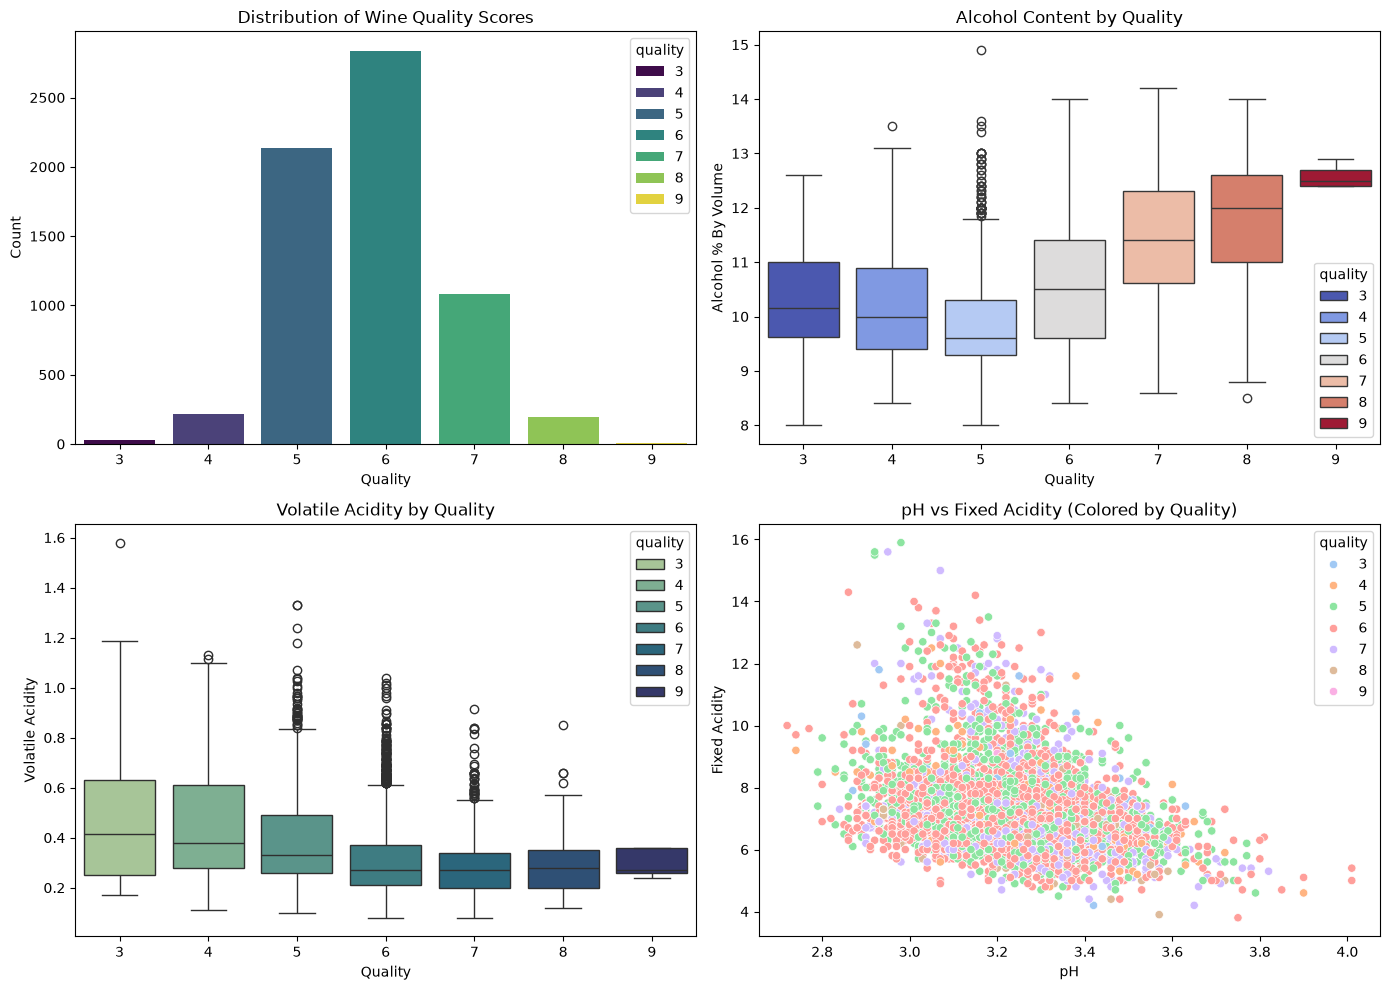

In [8]:
# Combine X and y into one dataframe if you haven't already
plt.figure(figsize=(14, 10))

# --- Subplot 1: Quality distribution ---
plt.subplot(2, 2, 1)
sns.countplot(x="quality", data=wine_df, palette="viridis", hue="quality")
plt.ylabel("Count")
plt.xlabel("Quality")
plt.title("Distribution of Wine Quality Scores")

# --- Subplot 2: Alcohol by Quality ---
plt.subplot(2, 2, 2)
sns.boxplot(x="quality", y="alcohol", data=wine_df, palette="coolwarm", hue="quality")
plt.ylabel("Alcohol % By Volume")
plt.xlabel("Quality")
plt.title("Alcohol Content by Quality")

# --- Subplot 3: Volatile Acidity by Quality ---
plt.subplot(2, 2, 3)
sns.boxplot(x="quality", y="volatile_acidity", data=wine_df, palette="crest", hue="quality")
plt.ylabel("Volatile Acidity")
plt.xlabel("Quality")
plt.title("Volatile Acidity by Quality")

plt.subplot(2, 2, 4)
sns.scatterplot(x="pH", y="fixed_acidity", data=wine_df, palette="pastel", hue="quality")
plt.ylabel("Fixed Acidity")
plt.title("pH vs Fixed Acidity (Colored by Quality)")

plt.tight_layout()
plt.show()

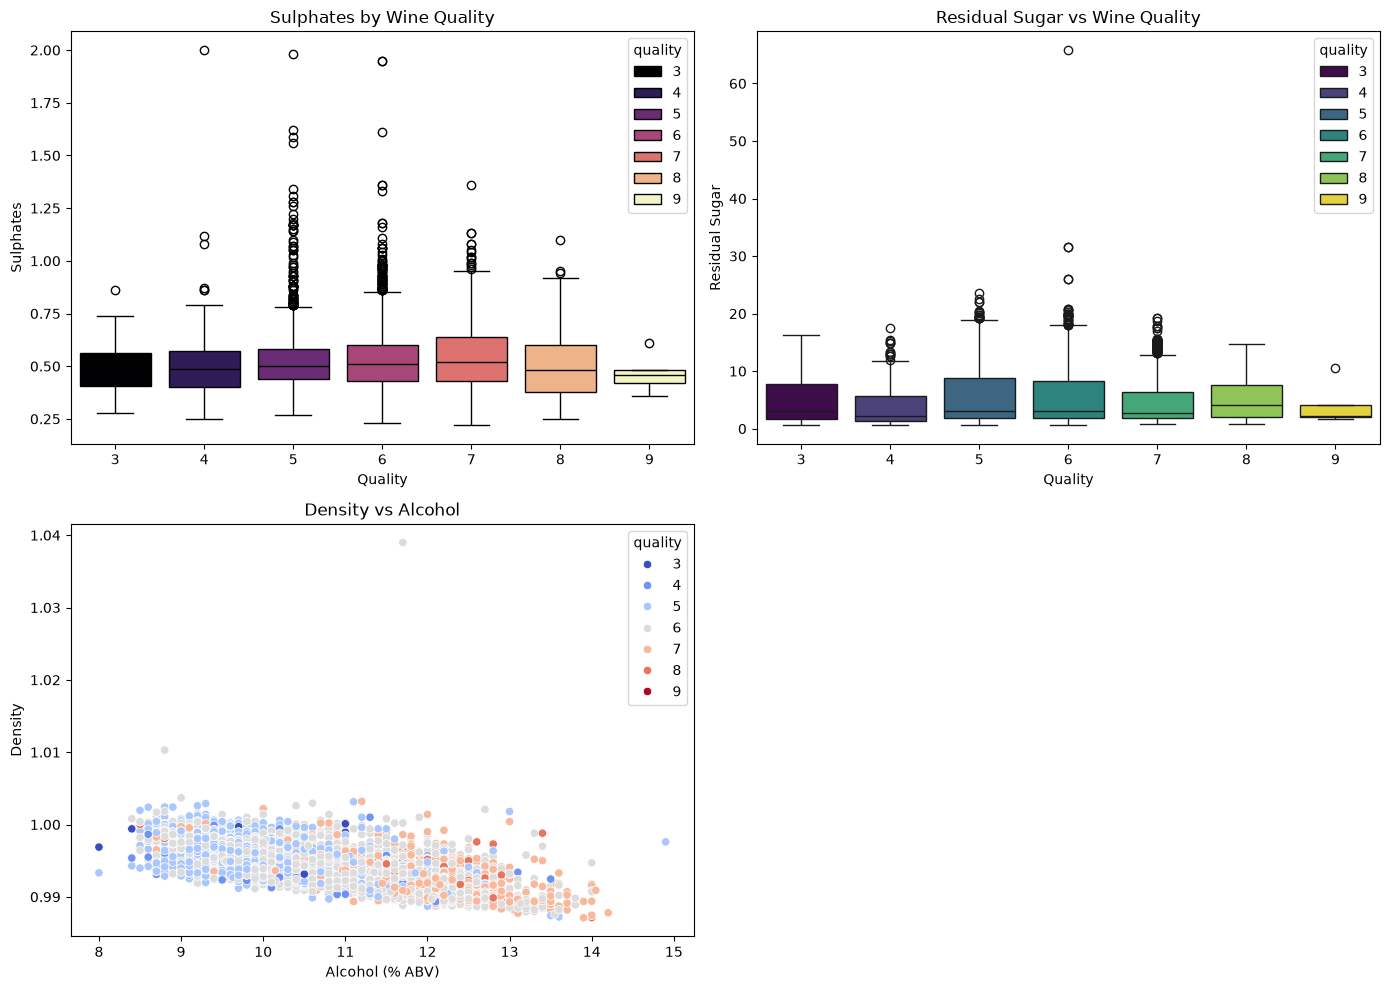

In [9]:
plt.figure(figsize=(14, 10))

# --- Subplot 1: Sulphates vs Quality (Boxplot) ---
plt.subplot(2, 2, 1)
sns.boxplot(data=wine_df, x="quality", y="sulphates", palette="magma", hue="quality",)
plt.title("Sulphates by Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Sulphates")

# --- Subplot 2: Residual Sugar vs Quality (Scatterplot) ---
plt.subplot(2, 2, 2)
sns.boxplot(data=wine_df, x="quality", y="residual_sugar", hue="quality", palette="viridis")
plt.title("Residual Sugar vs Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Residual Sugar")

# --- Subplot 3: Density vs Alcohol ---
plt.subplot(2, 2, 3)
sns.scatterplot(data=wine_df, x="alcohol", y="density", hue="quality", palette="coolwarm")
plt.title("Density vs Alcohol")
plt.xlabel("Alcohol (% ABV)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

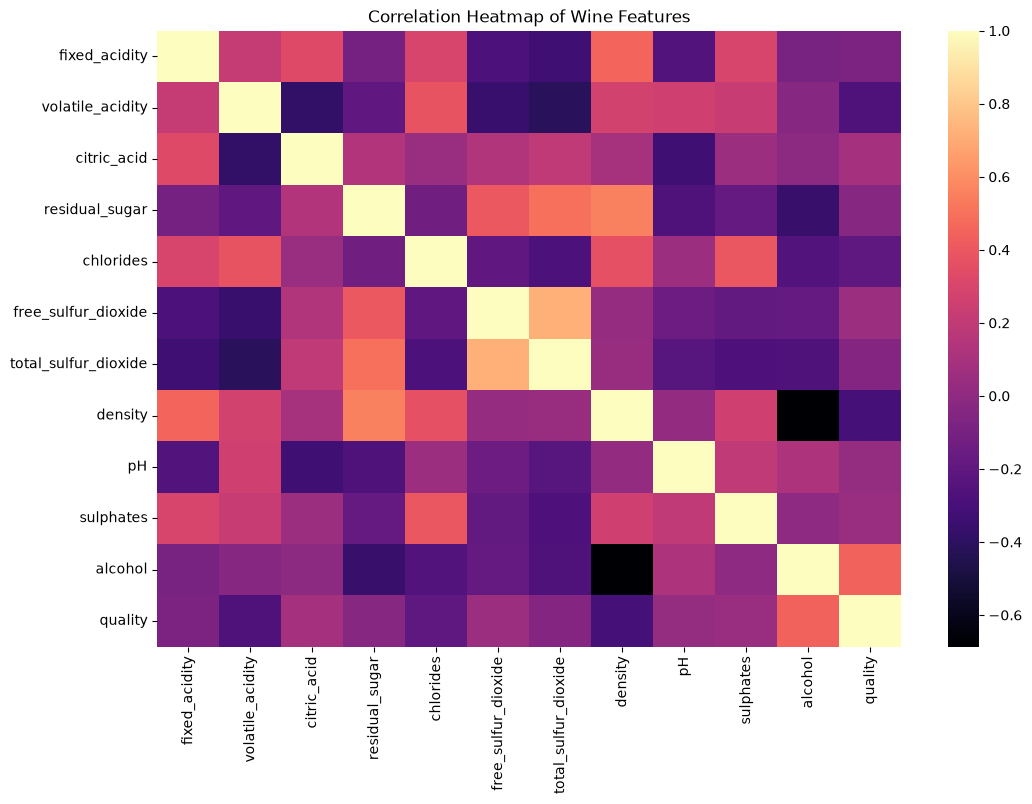

In [10]:
plt.figure(figsize=(12,8))
sns.heatmap(wine_df.corr(), annot=False, cmap="magma")
plt.title("Correlation Heatmap of Wine Features")
plt.show()

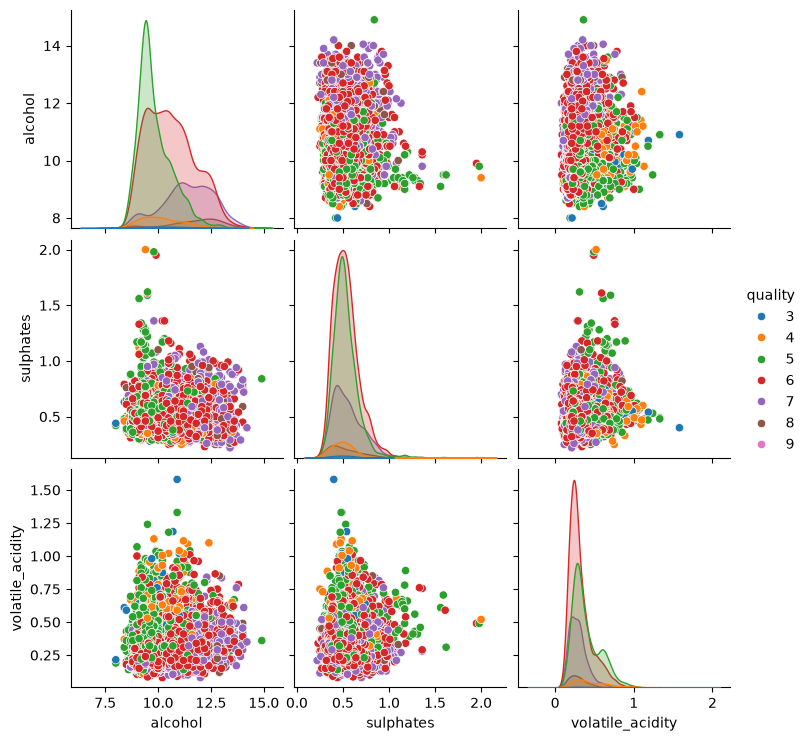

In [11]:
sns.pairplot(wine_df[["alcohol", "sulphates", "volatile_acidity", "quality"]],
             hue="quality", palette="tab10")
plt.show()

### Data Observations
`Quality` is an ordinal feature with a heavy distribution around 5 and 6. Using a Linear Regression model will cause predictions to pull towards 5 and 6.  
There is a direct correlation between `alcohol` and `quality`, and an inverse correlation between `volatile acitity` and `quality`.  
These two relationship mean a tree model would be a good choice.  
`Residual sugar`, `sulphates` and `density` have weak or noisy relationships, so a linear model would struggle.  
`Quality` itself is subjective and noisy, so even wines with similar chemistry can have different quality scores.

### Model Considerations

A Random Forest Regressor was chosen for this dataset for several reasons.  
A Random Forest handles nonlinear relationships well, as well as the interactions between features.  
It's also robust for handling outliers and works well with imbalanced targets.
This gives feature importance and performs well without needing heavy tuning.

In [12]:
X = wine_df.drop("quality", axis=1)
y = wine_df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
random_forest = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [14]:
y_pred = random_forest.predict(X_test)

In [15]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.43598
RMSE: 0.6073102793338965
R²: 0.5006060515453346


On average, the model is off by less than half a quality point, a Mean Absolute Error(`MAE`) of `0.44`, meaning it tracks well with a target quality range between 3-9 and is highly subjective.  
A typical error is around .6 quality points with the Root Mean Squared Error(`RMSE`) of `0.61`.  This is also very strong for the dataset.  
The Root Squared(`R`<sup>`2`</sup>) is `0.5`, about half of the variance in the wine quality. This is good becaues wine quality is a noisy feature, human-rated and influenced by factors outside the dataset.

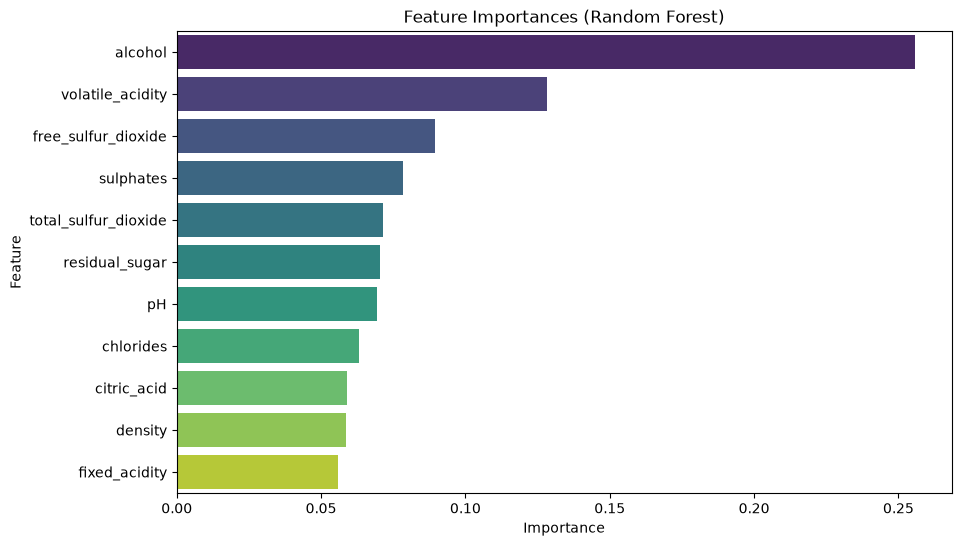

In [16]:
importances = random_forest.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
sns.barplot(x=importances[indices], y=X.columns[indices], palette="viridis", hue=X.columns[indices], legend=False)
plt.title("Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Model Results

Mapping the feature-importance reveals the chemical properties that matter the most for predicting wine quality.  
If there was one feature for predicting quality consistently, it's `alcohol`.  
`volatile acidity` is the next strongest predictor. According to the model, this hurts quality. Lower quality wines had higher volatile acitity.  
There are two compounds associated with volatile acitity, acetic acid and ethyl acetate. Acetic acid contributes a vinegar-like aroma to the wine and eythl acetate contributes more of a nail polish/nail polish remover aroma.

#### Research Question 1: **How do alcohol content and volatile acidity jointly influence wine quality?**

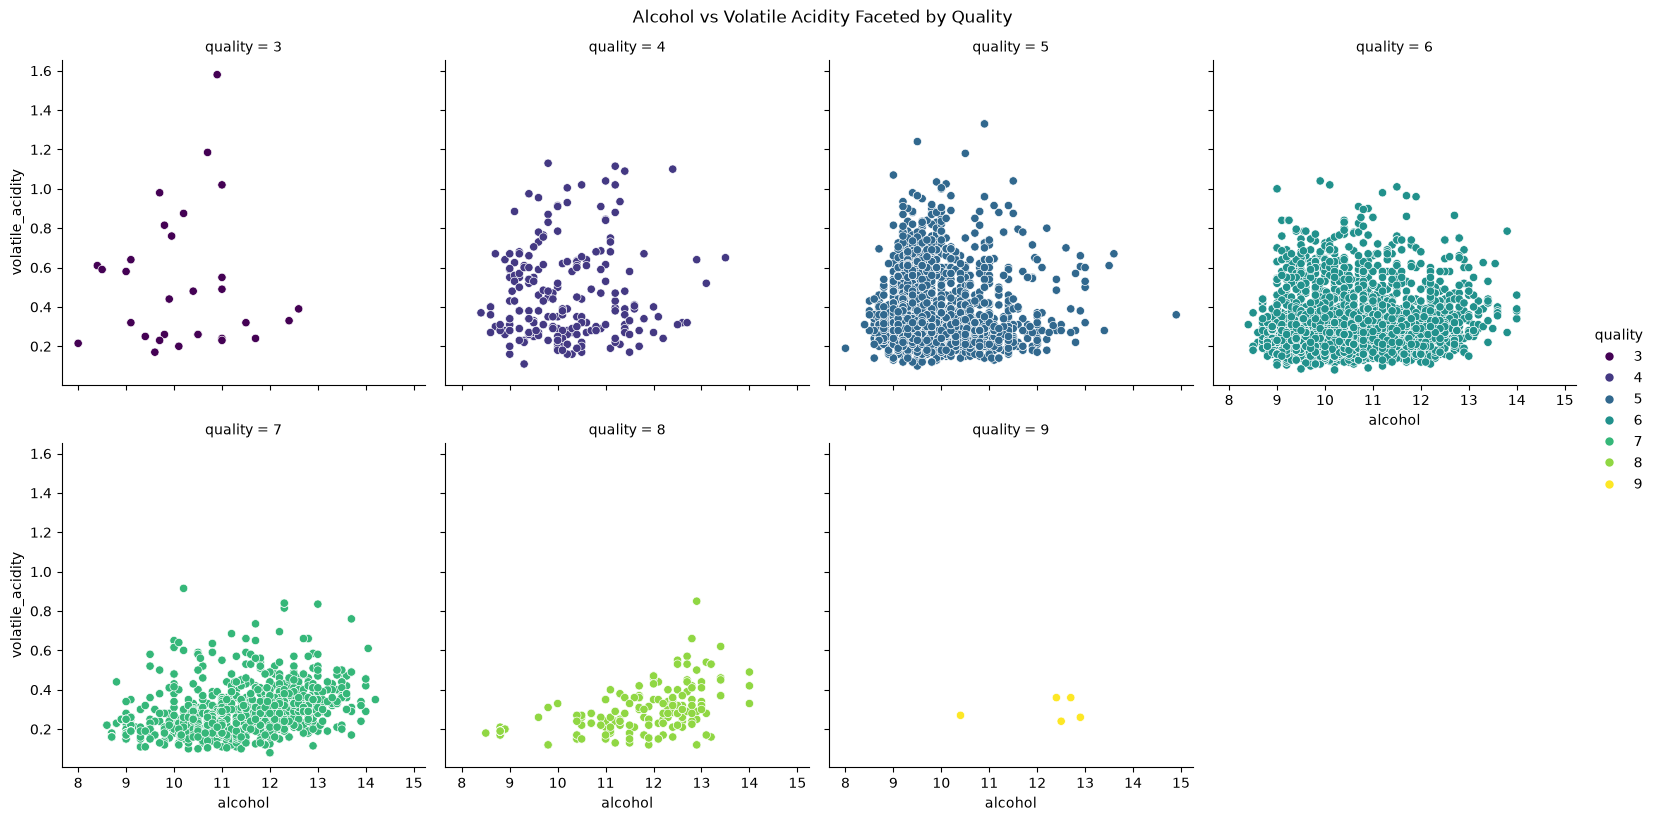

In [17]:
sns.relplot(
    data=wine_df,
    x="alcohol",
    y="volatile_acidity",
    col="quality",
    col_wrap=4,
    kind="scatter",
    palette="viridis",
    hue="quality",
    height=4
)
plt.suptitle("Alcohol vs Volatile Acidity Faceted by Quality", y=1.02)
plt.show()


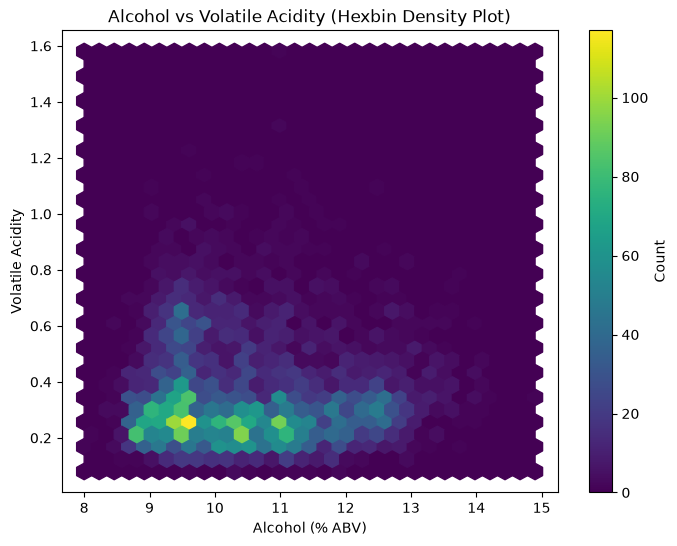

In [18]:
plt.figure(figsize=(8,6))
plt.hexbin(
    wine_df["alcohol"],
    wine_df["volatile_acidity"],
    gridsize=30,
    cmap="viridis"
)
plt.colorbar(label="Count")
plt.xlabel("Alcohol (% ABV)")
plt.ylabel("Volatile Acidity")
plt.title("Alcohol vs Volatile Acidity (Hexbin Density Plot)")
plt.show()

The Faceted plot shows across the quality plots for 7, 8 and 9, they consistently have higher alcohol levels(above ~10.5%) and lower volatile acidity(below 0.4). This is the "sweet spot" for good wines.  
Whereas lower quality wines have the opposite pattern, plots for 3 and 4 show alcohol is generally lower and volatile acidity is generally higher.  

The Hexbin plot shows the overall density for the relationship. This shows where most wines fall in the alcohol-volatile acidity space. There's a dense cluster around 9-11% alcohol and 0.2-0.4 volatile acidity.  
This is a typical wine region around most mid-quality(5 & 6). The hexbin also reveals there are few wines in the high-alcohol and low-volatile acidity region and few in the low-alcohol and high-volatile acidity region.  
Simply put, few wines are very high quality, and few wines are very poor quality. The distribution is largely spread through out the middle.

#### Research Question 2: **Are the distinct chemical profiles that differentiate high-quality wines(7-9) from mid-quality wines(5-6)?**

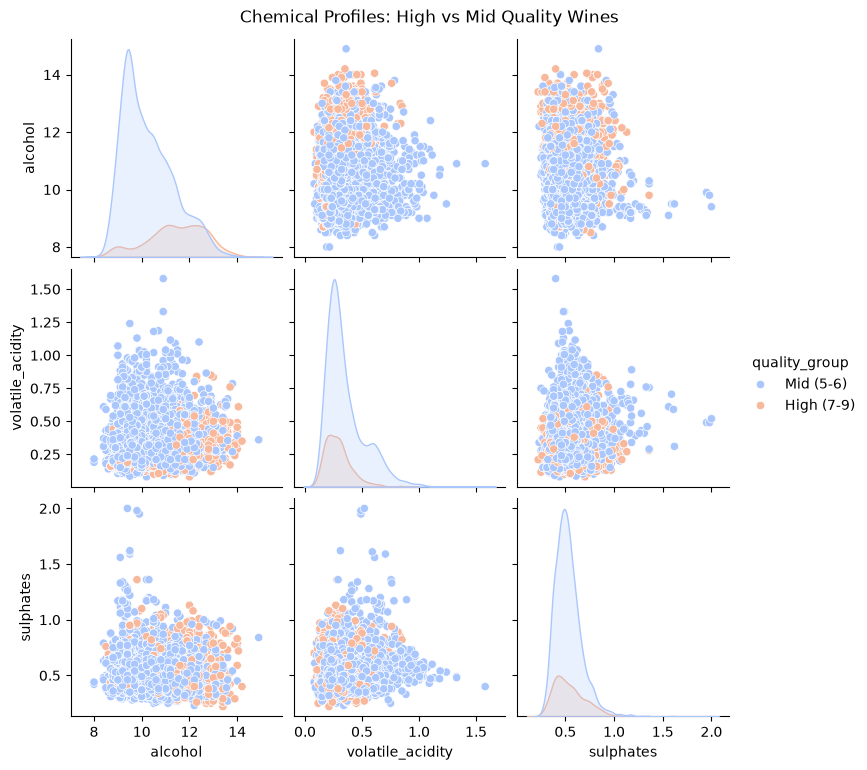

In [19]:
df_quality_groups = wine_df.copy()
df_quality_groups["quality_group"] = df_quality_groups["quality"].apply(
    lambda x: "High (7-9)" if x >= 7 else "Mid (5-6)"
)

sns.pairplot(
    df_quality_groups,
    vars=["alcohol", "volatile_acidity", "sulphates"],
    hue="quality_group",
    palette="coolwarm"
)
plt.suptitle("Chemical Profiles: High vs Mid Quality Wines", y=1.02)
plt.show()

The pairplot for high and low quality wines as compared to their chemical profiles reveals high-quality wines have noticeably higher alcohol levels.  
Looking at the diagonal KDE for alcohol. The orange curve(high quality) is shifted to the right whereas the blue curve(mid quality) is centered lower. This shows that high-quality wines have consistently higher alcohol.  

Looking at the volatile acidity diagonal KDE, the orange curve(high quailty) is shifted lower while the blue curve(mid quailty) is higher.  
The scatter plots also show the orange points cluster in the low-volatile acidity region, and the blue points are spread into higher volatile acidity values.  
This indicates that higher quality wines tend to have cleaner ferementation and fewer vinegars-like compounds.  

Sulphates don't separate as dramatically, but there are distinct differences the orange points lean slightly higher while the blue points cluster lower. This would suggest sulphates play a supporting role in stabalizing and enhancing wine quality.

#### Research Question 3: **Which chemical features contribute most to prediction errors, and what does that reveal about the limitations of using chemistry alone to predict wine quality?**

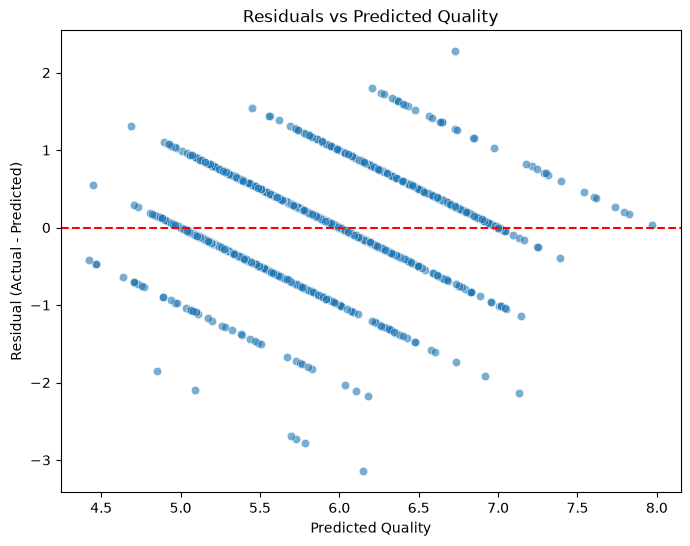

In [20]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Quality")
plt.xlabel("Predicted Quality")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()


Calculating and plotting the residuals reveals that the model predicts mid-range(5-6) qualities very well.  
Residuals cluster tightly around 0 with very little vertical spread. Predictions around 5 and 6 have small errors.  
This follows that most wines in the datasets are 5-6 quality. The chemistry for these wines is consistent and predictable.

The model strugles more with high quality(7+) wines. The residuals start to spread out more above 7, meaning the errors are larger and more variable.  
Sometimes the model underpredicts high-quality wines.  Quality is largely subjective and the chemistry that makes up these wines is more variable.  
There are many factors outside the dataset that determine a quality of 7-9 suchas aroma, color, grape variety, mouthfeel.

The same is also true for low quality wines(3-4). Residuals here are also wide. Much like high quality wines, low quality wines are also rare.  
Their chemistry overlaps with mid-quality wines. The quality level of 3-4 often reflects flaws such as oxidation or off-aromas that aren't captured by chemical measuerments.

In short, chemistry can only explain so much about wine quality. the R<sup>2</sup> value, 0.5, hinted at this.  
About half of wine quality variation is predictable from chemistry while the other half comes from sensory factors not represented in the dataset.  
The model is hitting the natural limit of what chemistry alone can explain.